In [4]:
library(tidyverse)
library(ggplot2)

In [1]:
africa <- read.csv("data/africa.csv")
head(africa)

,language,family,native_speakers,country
,<chr>,<chr>,<int>,<chr>
1,ǂKxʼaoǁʼae,Kxʼa,5000,Namibia
2,ǂKxʼaoǁʼae,Kxʼa,5000,Botswana
3,Abon,Niger–Congo,800,Cameroon
4,Abron,Niger–Congo,1393000,Ghana
5,Abron,Niger–Congo,1393000,Ivory Coast
6,Acheron,Niger–Congo,20000,Sudan


In [3]:
family_summary <- africa |>
    group_by(family) |>
    summarise(
        total_speakers = sum(native_speakers, na.rm = TRUE),
        num_languages = n_distinct(language)
    ) |>
    mutate(
        speaker_percentage = (total_speakers / sum(total_speakers)) * 100
    ) |>
    arrange(desc(total_speakers))

head(family_summary)

family,total_speakers,num_languages,speaker_percentage
<chr>,<dbl>,<int>,<dbl>
Afroasiatic,2369939800,17,59.4561936
Niger–Congo,1353163982,383,33.9476892
Nilo-Saharan,111091000,70,2.7870109
Indo-European,101665300,4,2.5505423
Kongo-based,26000000,1,0.6522786
Austronesian,18000000,1,0.4515775


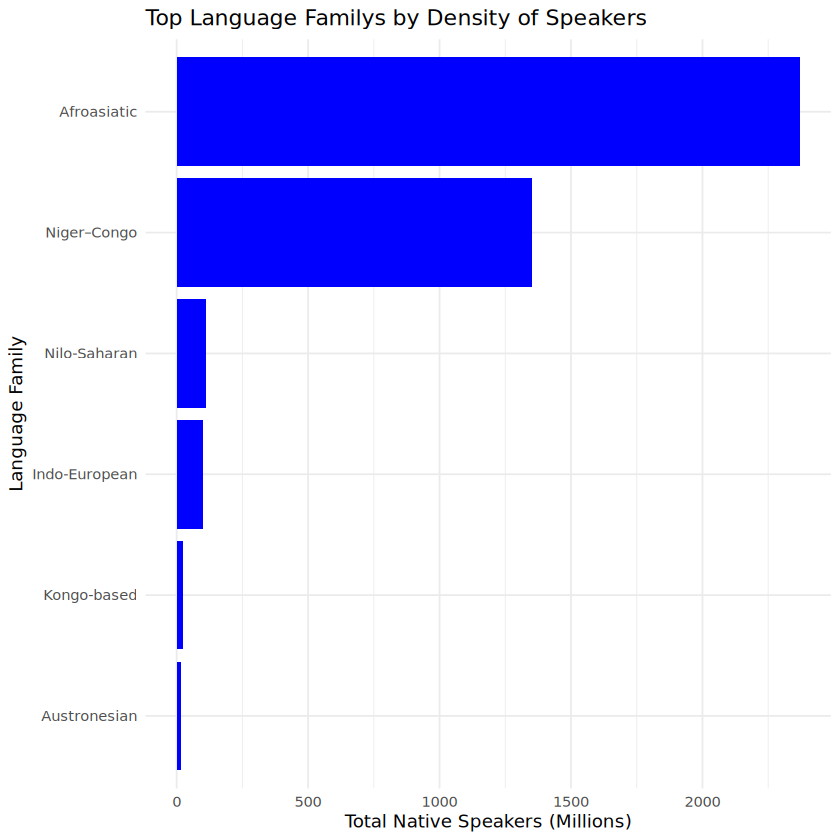

In [11]:
family_summary |>
    filter(total_speakers >= 10e6) |>
    ggplot(aes(x= reorder(family, total_speakers), y = total_speakers / 1e6)) +
    geom_col(fill = "blue") +
    coord_flip() +
    labs(
        title = "Top Language Familys by Density of Speakers",
        x="Language Family",
        y="Total Native Speakers (Millions)"
    ) +
    theme_minimal()

In [12]:
ggsave("images/language_density.png",)

Saving 6.67 x 6.67 in image
